Training plots:

In [1]:
from matplotlib import pyplot as plt
import json

In [2]:
log_gpt2 = json.load(open("checkpoints/gpt2_history.json"))
log_sp = json.load(open("checkpoints/sentencepiece_history.json"))
log_ws = json.load(open("checkpoints/whitespace_history.json"))

In [3]:
xs_train = [x['step'] for x in log_gpt2["train"]]
xs_val =[x['step'] for x in log_gpt2["validation"]]

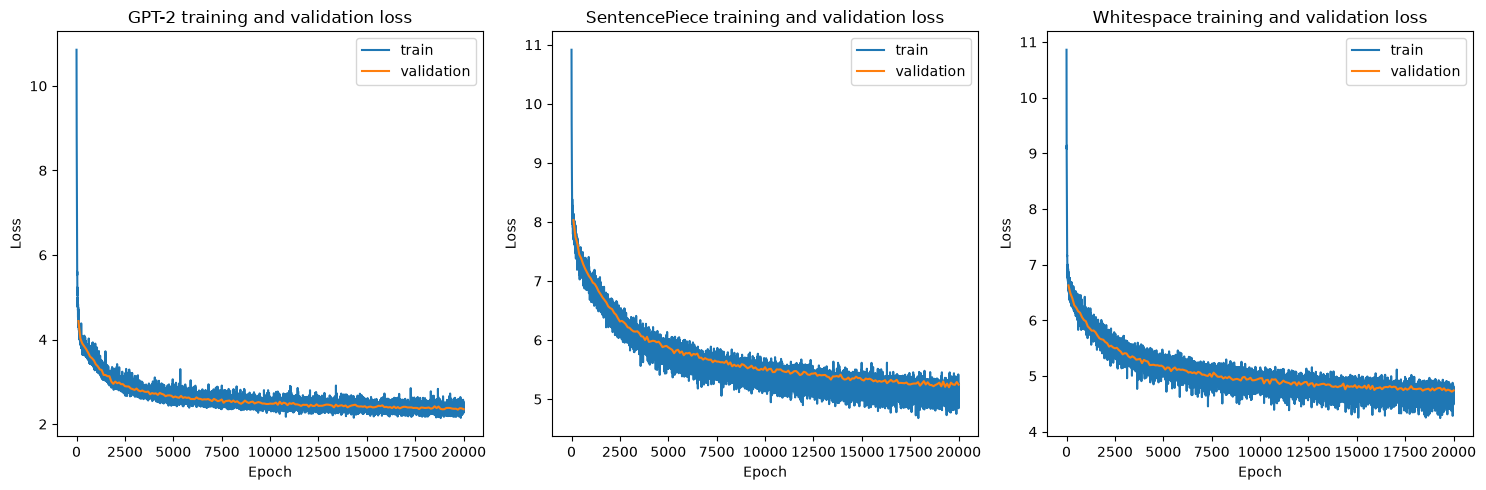

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].plot(xs_train, [y['loss'] for y in log_gpt2["train"]], label="train")
axs[0].plot(xs_val, [y['loss'] for y in log_gpt2["validation"]], label="validation")
axs[0].set_title("GPT-2 training and validation loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()

axs[1].plot(xs_train, [y['loss'] for y in log_sp["train"]], label="train")
axs[1].plot(xs_val, [y['loss'] for y in log_sp["validation"]], label="validation")
axs[1].set_title("SentencePiece training and validation loss")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Loss")
axs[1].legend()

axs[2].plot(xs_train, [y['loss'] for y in log_ws["train"]], label="train")
axs[2].plot(xs_val, [y['loss'] for y in log_ws["validation"]], label="validation")
axs[2].set_title("Whitespace training and validation loss")
axs[2].set_xlabel("Epoch")
axs[2].set_ylabel("Loss")
axs[2].legend()

plt.tight_layout()
plt.show()

Loading tokenizers

In [5]:
from custom_tokenizers import WhiteSpaceTokenizer, SentencePieceBPETokenizer, GPT2BPETokenizer

In [6]:
whitespace_tokenizer = WhiteSpaceTokenizer()
sentencepiece_tokenizer = SentencePieceBPETokenizer()
gpt2_tokenizer = GPT2BPETokenizer()

whitespace_tokenizer.load("models/ws.model")
sentencepiece_tokenizer.load("models/sp_bpe.model")

Loading transformer models

In [7]:
import torch
from nano_gpt import GPT, GPTConfig

def load_model(path, device):
    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=True,
    )

    config = GPTConfig(**checkpoint["config"])
    model = GPT(config)
    model.load_state_dict(checkpoint["model"])
    model.to(device)
    model.eval()

    return model

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [9]:
model_gpt2_tokenizer = load_model("checkpoints/gpt2.pt", device)
model_sp_tokenizer = load_model("checkpoints/sentencepiece.pt", device)
model_ws_tokenizer = load_model("checkpoints/whitespace.pt", device)

number of parameters: 29.92M
number of parameters: 29.92M
number of parameters: 29.92M


In [10]:
class TextGenerator:
    def __init__(self, model, tokenizer, device):
        self.model = model
        self.tokenizer = tokenizer
        self.device = device

    def generate(self, prompt, max_new_tokens=100, temperature=0.8, top_k=50):
        prompt_ids = self.tokenizer.encode(prompt)
        x = torch.tensor(
            [prompt_ids],
            dtype=torch.long,
            device=self.device,
        )
        with torch.no_grad():
            generated_ids = self.model.generate(
                x,
                max_new_tokens=max_new_tokens,
                temperature=temperature,
                top_k=top_k,
            )[0].tolist()
        return self.tokenizer.decode(generated_ids)

In [11]:
text_generator_gpt2 = TextGenerator(model_gpt2_tokenizer, gpt2_tokenizer, device)
text_generator_sp = TextGenerator(model_sp_tokenizer, sentencepiece_tokenizer, device)
text_generator_ws = TextGenerator(model_ws_tokenizer, whitespace_tokenizer, device)

In [12]:
print(text_generator_sp.generate("Napisz mi wiersz w stylu romantycznym", max_new_tokens=200))

Napisz mi wiersz w stylu romantycznym, ale to nie wystarcza. Już mi wystarczy, ale z pewnością nie będę mógł mówić o życiu. Z początku nie mogę mówić o tobie, to nie jest w istocie; nie mógłbym powiedzieć. — Nie, nie mogę sobie nic powiedzieć, jedynie dlatego, że nie chcę cię widzieć, że za chwilę, po wpół z całą stanowczością, z tą samą radością, w jakiej się kocha; ale jeśli kochasz, będziesz się już kochał na chwilę. — Panie! — wykrzyknęła. — A może pan nie myśli, że, jak pan mówi, kiedy się kocha? — Och, jak ja kocham panią, czuję się kochaną w miłości! — Ale nie, nie! — Ależ nie! — Niech pan mówi do mnie, niech pani mówi: „Pani kocha mnie dobrze, że nie kocham więcej, niż pan mówi, że on ubóstwia mnie”. — A! — rzekł pan de Cadignard, który jeszcze nie poznał mnie, ale — dodał pan de Cadignan — czy pan wie, czy nie


In [13]:
print(text_generator_sp.generate("Napisz mi wiersz w stylu romantycznym", max_new_tokens=200))

Napisz mi wiersz w stylu romantycznym, a nie w sposób, aby z niej skończyć. Z tego powodu jest to wszystko, co się na ciebie zwraca, i co robi! — Ale to nie jest możliwe, aby tylko przeczytać: „nie warto mieć więcej” — to nie jest możliwe. — O ile mnie nie ma? — A czy nie ma więcej? — Nie, tak jest. — Więc nie chcę. To niemożliwe. — Nie chcę być już na miejscu, poza które się nie mieści. — Ale nie mam nic do roboty. — Nie chcę mieć. — Nie mam nic do roboty. — Ale co mnie ze mnie obchodzi? — To prawda. — Więc ja nie chcę. — Wiem, że nie. — Bo na przykład nie chcę, ale mam prawo, żebym się miał stać dla mnie czymś więcej jak tylko fikcją, to znaczy jest, jak ja to powiem, czy nie. — Rozumiem — to jest coś, co to jest nasze życie. — A cóż to znaczy, kiedy ktoś nie chce, że jest ktoś


In [14]:
print(text_generator_ws.generate("Pewnego dnia"))

Pewnego dnia rano przyszła mi do głowy na myśl , że mnie <UNK> , po krótkim czasie , przed <UNK> laty , który mnie kochał . <UNK> mnie , jak gdyby mnie kochał jako <UNK> , był bardzo <UNK> . <UNK> i <UNK> się do <UNK> . Pewnego dnia , kiedy to była tylko sobota , o szóstej rano , w nocy i nocy , <UNK> mnie w <UNK> i tym bardziej , że nie wiedziałem nawet , jak mnie to kosztowało , ale teraz jestem kompletnie <UNK> . Byłem tak znużony , że nie mogłem się uspokoić . Nie mogłem nawet


Metrics

In [15]:
from pathlib import Path

CHUNK_SIZE = 1024 * 1024

def encode_file(path: Path, tokenizer):
    encoded_chunks = []

    with path.open("r", encoding="utf-8") as file:
        while chunk := file.read(CHUNK_SIZE):
            # Dociągamy tekst do końca linii, tak jak w encode_dataset.py
            chunk += file.readline()
            encoded_chunks.append(
                np.asarray(tokenizer.encode(chunk), dtype=np.uint16)
            )

    return np.concatenate(encoded_chunks)

In [16]:
import numpy as np

def create_test_batches(token_ids, block_size, batch_size):
    target_count = len(token_ids) - 1
    full_blocks = target_count // block_size

    for first_block in range(0, full_blocks, batch_size):
        blocks = min(batch_size, full_blocks - first_block)
        start = first_block * block_size
        end = start + blocks * block_size

        x = token_ids[start:end].astype(np.int64)
        y = token_ids[start + 1:end + 1].astype(np.int64)

        yield (
            x.reshape(blocks, block_size),
            y.reshape(blocks, block_size),
        )

    remainder_start = full_blocks * block_size

    if remainder_start < target_count:
        x = token_ids[remainder_start:-1].astype(np.int64)
        y = token_ids[remainder_start + 1:].astype(np.int64)
        yield x[None, :], y[None, :]

In [17]:
TEST_PATH = Path("corpus/test.txt")

In [18]:
import math

import torch
import re
from tqdm.auto import tqdm

@torch.inference_mode()
def evaluate_test(
    model,
    tokenizer,
    test_path=TEST_PATH,
    batch_size=8,
    unk_id=None,
):
    model.eval()
    device = next(model.parameters()).device
    token_ids = encode_file(test_path, tokenizer)

    total_nll = 0.0
    total_tokens = 0
    correct_tokens = 0

    batches = create_test_batches(
        token_ids,
        model.config.block_size,
        batch_size,
    )

    for x_numpy, y_numpy in tqdm(batches, desc="Test"):
        x = torch.from_numpy(x_numpy).to(device)
        y = torch.from_numpy(y_numpy).to(device)

        logits, loss = model(x, y)

        target_count = y.numel()
        total_nll += loss.item() * target_count
        total_tokens += target_count
        correct_tokens += (logits.argmax(dim=-1) == y).sum().item()

    test_text = test_path.read_text(encoding="utf-8")

    word_count = len(
        re.findall(r"\w+", test_text, flags=re.UNICODE)
    )
    character_count = len(test_text)

    word_nll = total_nll / word_count
    character_nll = total_nll / character_count

    metrics = {
        "word_perplexity": math.exp(word_nll),
        "character_perplexity": math.exp(character_nll),
        "nll_per_word": word_nll,
        "nll_per_character": character_nll,
        "word_count": word_count,
        "character_count": character_count,
        "test_tokens": len(token_ids),
    }

    if unk_id is not None:
        metrics["unk_rate"] = float(
            np.count_nonzero(token_ids == unk_id) / len(token_ids)
        )

    return metrics

In [32]:
metrics_gpt2 = evaluate_test(model_gpt2_tokenizer, gpt2_tokenizer, unk_id = gpt2_tokenizer.tokenizer.unk_token_id)
metrics_ws = evaluate_test(model_ws_tokenizer, whitespace_tokenizer, unk_id = whitespace_tokenizer.unk_token_id)
metrics_sp = evaluate_test(model_sp_tokenizer, sentencepiece_tokenizer, unk_id = sentencepiece_tokenizer.tokenizer.unk_id)

Test: 0it [00:00, ?it/s]

Test: 0it [00:00, ?it/s]

Test: 0it [00:00, ?it/s]

In [33]:
import pandas as pd
df_metrics = pd.DataFrame({
    "gpt2": metrics_gpt2,
    "whitespace": metrics_ws,
    "sentencepiece": metrics_sp
}).T
df_metrics

,word_perplexity,character_perplexity,nll_per_word,nll_per_character,word_count,character_count,test_tokens,unk_rate
gpt2,6708.074851,3.722725,8.811067,1.314456,1621945.0,10872230.0,6016927.0,0.000000
whitespace,359.240077,2.405572,5.883991,0.877788,1621945.0,10872230.0,2004373.0,0.113745
sentencepiece,2319.371421,3.177268,7.749051,1.156022,1621945.0,10872230.0,2398549.0,0.000000


<Axes: title={'center': 'Word Perplexity by Model'}>

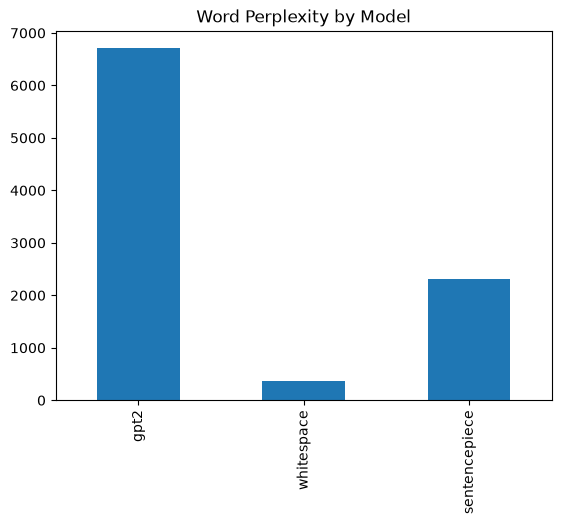

In [28]:
df_metrics["word_perplexity"].plot(kind="bar", title="Word Perplexity by Model")

<Axes: title={'center': 'Test Tokens/Word by Tokenizer'}>

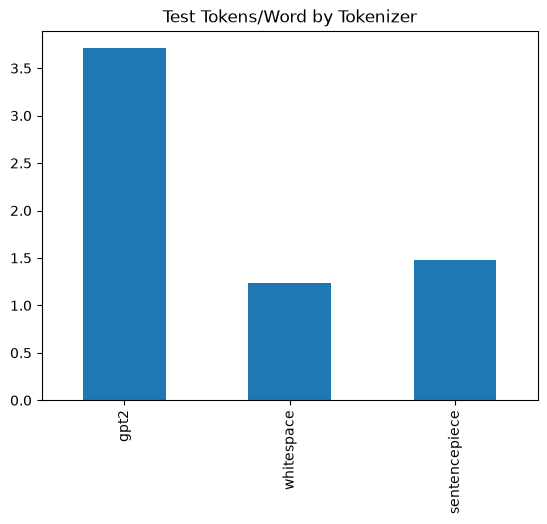

In [35]:
(df_metrics["test_tokens"] / df_metrics["word_count"]).plot(kind="bar", title="Test Tokens/Word by Tokenizer")